# Size normalization validation

Resize independently to heights 32, 48, 64, 96 and 128 pixels, preserving aspect ratio to the nearest integer width (minimum one pixel), using Pillow LANCZOS. No cropping, padding, intensity normalization or grayscale conversion is applied. TrOCR still applies its mandatory processor resizing consistently: this tests an extra resampling stage, not a change to model input dimensions.

Compare baseline and each active configuration on the same pinned 100 IAM and 100 Bentham validation samples (seed 42 from the completed denoising study). Restore dataset and checkpoint revisions, source indices, batch size and generation settings from its metadata. Original images and transcriptions are preserved; RGBA is composited onto white for all configurations. Collapse whitespace, retaining case and punctuation for corpus CER/WER. Rank by equal-dataset mean corpus CER, then WER, with baseline eligible.

Run cells in order; rerun only the evaluation cell to resume in this session. Results go to results/validation/size_normalization/<UTC study ID>/. No training or test evaluation. The saved outputs contain the completed subset validation comparison; confirm conclusions on broader validation data before freezing final test parameters.

In [1]:
import sys
from pathlib import Path
import json
import random
from datetime import datetime, timezone
from importlib.metadata import version
import numpy as np
import torch

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/load_dataset/iam.py').exists())
sys.path.insert(0, str(ROOT))
from src.load_dataset.iam import load_iam_dataset
from src.load_dataset.bentham import load_bentham_dataset, REVISION, ARCHIVES
from src.models.trocr import TrOCRRecognizer
from src.validation.size_normalization import configurations, evaluate, summarize

# Explicit reference pins this comparison to the completed denoising study.
REFERENCE = ROOT / 'results/validation/denoising/20261112T000633091905Z/metadata.json'
reference = json.loads(REFERENCE.read_text())
SEED = reference['seed']
BATCH_SIZE = reference['batch_size']
indices = reference['sample_indices']
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
assert reference['bentham_revision'] == REVISION
full_iam = load_iam_dataset('validation', revision=reference['iam_revision'])
full_bentham = load_bentham_dataset('validation')
assert {'iam': len(full_iam), 'bentham': len(full_bentham)} == reference['full_split_sizes']
iam = full_iam.select(indices['iam']).add_column('id', [f'sample_{i}' for i in indices['iam']])
bentham = full_bentham.select(indices['bentham'])
assert len(iam) == len(bentham) == 100
print('Validation subsets:', len(iam), len(bentham))
print('Modes:', iam[0]['image'].mode, bentham[0]['image'].mode)
print('Columns:', iam.column_names, bentham.column_names)

Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields


Validation subsets: 100 100
Modes: L RGBA
Columns: ['image', 'text', 'id'] ['id', 'image', 'text']


In [2]:
model = TrOCRRecognizer(checkpoint=reference['model']['checkpoint'],
    revision=reference['model']['revision'], device=reference['model']['device'],
    generation_kwargs=reference['model']['generation_kwargs'])
configs = configurations()
OUTPUT = ROOT / 'results/validation/size_normalization' / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
OUTPUT.mkdir(parents=True)
metadata = {'seed': SEED, 'split': 'validation', 'batch_size': BATCH_SIZE,
    'sample_indices': indices, 'sample_count_per_dataset': 100, 'size_normalization_run_count': 5,
    'reference_study': str(REFERENCE.relative_to(ROOT)),
    'iam_revision': reference['iam_revision'], 'bentham_revision': REVISION,
    'bentham_archive_sha256': ARCHIVES, 'full_split_sizes': reference['full_split_sizes'],
    'datasets': {name: {'count': len(ds), 'fingerprint': ds._fingerprint, 'columns': ds.column_names} for name, ds in [('iam', iam), ('bentham', bentham)]},
    'model': model.to_config(),
    'configurations': {name: step.to_config() if step else None for name, step in configs.items()},
    'selection': 'lowest equal-dataset mean corpus CER; WER tie-breaker; baseline eligible',
    'normalization': 'collapse whitespace, retain case and punctuation',
    'input_adaptation': 'RGBA white composite; preserve L/RGB',
    'scope': 'seeded validation subset parameter search, not final test evaluation',
    'versions': {p: version(p) for p in ['torch', 'transformers', 'datasets', 'huggingface-hub', 'Pillow', 'numpy', 'pandas', 'jiwer', 'opencv-python-headless', 'matplotlib']}}
(OUTPUT / 'metadata.json').write_text(json.dumps(metadata, indent=2))
print('Output:', OUTPUT)
print(json.dumps(metadata['configurations'], indent=2))

W1111 20:09:50.717000 18821 .venv/lib/python3.13/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/478 [00:00<?, ?it/s]

[transformers] VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-base-handwritten
Key                         | Status  | 
----------------------------+---------+-
encoder.pooler.dense.weight | MISSING | 
encoder.pooler.dense.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Output: /Users/vmendoza/Documents/Lakehead/RM/COMP-5112-Research-Methodology/results/validation/size_normalization/20261112T010953112528Z
{
  "baseline": null,
  "size_height32": {
    "name": "size_normalization",
    "enabled": true,
    "target_height": 32,
    "resampling": "LANCZOS",
    "preserve_aspect_ratio": true,
    "width_rounding": "nearest integer, ties to even; minimum 1"
  },
  "size_height48": {
    "name": "size_normalization",
    "enabled": true,
    "target_height": 48,
    "resampling": "LANCZOS",
    "preserve_aspect_ratio": true,
    "width_rounding": "nearest integer, ties to even; minimum 1"
  },
  "size_height64": {
    "name": "size_normalization",
    "enabled": true,
    "target_height": 64,
    "resampling": "LANCZOS",
    "preserve_aspect_ratio": true,
    "width_rounding": "nearest integer, ties to even; minimum 1"
  },
  "size_height96": {
    "name": "size_normalization",
    "enabled": true,
    "target_height": 96,
    "resampling": "LANCZOS",
    "

In [3]:
summaries = []
for name, transform in configs.items():
    for dataset_name, dataset in [('iam', iam), ('bentham', bentham)]:
        result = evaluate(dataset, dataset_name, model, name, transform, OUTPUT, BATCH_SIZE)
        summaries.append(result)
        print(result, flush=True)
        if len(summaries) >= 2:
            table, ranking, winners = summarize(summaries, OUTPUT)
assert len(summaries) == 2 * len(configs)
assert all(row['sample_count'] == 100 for row in summaries)
table, ranking, winners = summarize(summaries, OUTPUT)
display(table, ranking, winners)

iam/baseline: 8/100
iam/baseline: 80/100
iam/baseline: 100/100
{'dataset': 'iam', 'configuration': 'baseline', 'sample_count': 100, 'cer': 0.011541072640868975, 'wer': 0.0438034188034188, 'preprocessing_seconds': 0.001293331995839253, 'inference_seconds': 37.25098049999542}
bentham/baseline: 8/100
bentham/baseline: 80/100
bentham/baseline: 100/100
{'dataset': 'bentham', 'configuration': 'baseline', 'sample_count': 100, 'cer': 0.15963923337091318, 'wer': 0.2954796030871003, 'preprocessing_seconds': 0.03345463100049528, 'inference_seconds': 28.34168937600225}
iam/size_height32: 8/100
iam/size_height32: 80/100
iam/size_height32: 100/100
{'dataset': 'iam', 'configuration': 'size_height32', 'sample_count': 100, 'cer': 0.01787734781624802, 'wer': 0.056623931623931624, 'preprocessing_seconds': 0.05313370800104167, 'inference_seconds': 29.230048291001367}
bentham/size_height32: 8/100
bentham/size_height32: 80/100
bentham/size_height32: 100/100
{'dataset': 'bentham', 'configuration': 'size_heig

,dataset,configuration,sample_count,cer,wer,preprocessing_seconds,inference_seconds,cer_delta_vs_baseline,wer_delta_vs_baseline
0,iam,baseline,100,0.011541,0.043803,0.001293,37.250980,0.000000,0.000000
1,bentham,baseline,100,0.159639,0.295480,0.033455,28.341689,0.000000,0.000000
2,iam,size_height32,100,0.017877,0.056624,0.053134,29.230048,0.006336,0.012821
3,bentham,size_height32,100,0.246674,0.406836,0.156579,29.390155,0.087035,0.111356
4,iam,size_height48,100,0.012673,0.047009,0.058846,29.556356,0.001131,0.003205
5,bentham,size_height48,100,0.179256,0.319735,0.167439,28.567907,0.019617,0.024256
6,iam,size_height64,100,0.012899,0.047009,0.070304,29.499832,0.001358,0.003205
7,bentham,size_height64,100,0.171590,0.313120,0.186716,30.115735,0.011950,0.017641
8,iam,size_height96,100,0.012673,0.047009,0.106039,29.767274,0.001131,0.003205
9,bentham,size_height96,100,0.158737,0.293275,0.207206,28.721763,-0.000902,-0.002205


,cer,wer
configuration,,
size_height128,0.084801,0.169090
baseline,0.085590,0.169642
size_height96,0.085705,0.170142
size_height64,0.092244,0.180064
size_height48,0.095964,0.183372
size_height32,0.132276,0.231730


,dataset,configuration,sample_count,cer,wer,preprocessing_seconds,inference_seconds,cer_delta_vs_baseline,wer_delta_vs_baseline
0,bentham,size_height128,100,0.158061,0.294377,0.261488,29.947659,-0.001578,-0.001103
1,iam,baseline,100,0.011541,0.043803,0.001293,37.250980,0.000000,0.000000


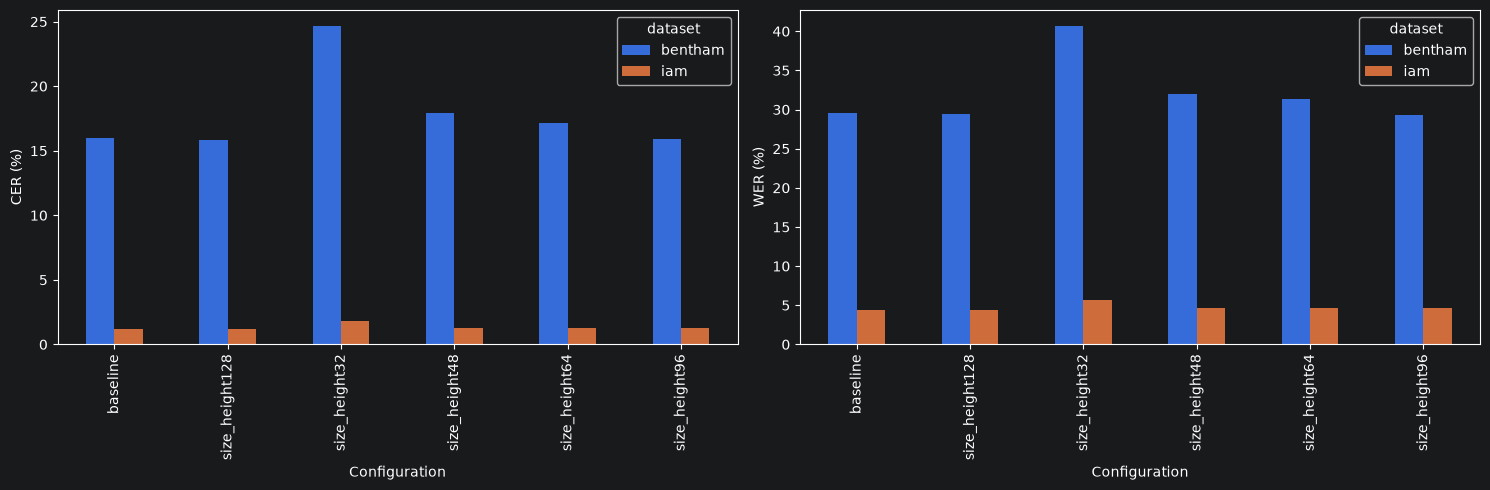

{
  "best_overall": "size_height128",
  "best_size_normalization": "size_height128",
  "size_normalization_parameters": {
    "name": "size_normalization",
    "enabled": true,
    "target_height": 128,
    "resampling": "LANCZOS",
    "preserve_aspect_ratio": true,
    "width_rounding": "nearest integer, ties to even; minimum 1"
  },
  "criterion": "lowest equal-dataset mean corpus CER; WER tie-breaker; baseline eligible",
  "dataset_winners": [
    {
      "dataset": "bentham",
      "configuration": "size_height128",
      "cer": 0.1580608793686584,
      "wer": 0.29437706725468576
    },
    {
      "dataset": "iam",
      "configuration": "baseline",
      "cer": 0.011541072640868975,
      "wer": 0.0438034188034188
    }
  ]
}
Subset validation optimum; confirm on validation data before freezing final test parameters.


In [4]:
import matplotlib.pyplot as plt
assert len(table) == 2 * len(configs) and table.sample_count.eq(100).all()
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, metric in zip(axes, ['cer', 'wer']):
    table.pivot(index='configuration', columns='dataset', values=metric).mul(100).plot.bar(ax=ax)
    ax.set_ylabel(metric.upper() + ' (%)')
    ax.set_xlabel('Configuration')
fig.tight_layout()
fig.savefig(OUTPUT / 'corpus_error_rates.png', dpi=160, bbox_inches='tight')
plt.show()
best_size_normalization = ranking.drop(index='baseline').index[0]
selection = {'best_overall': ranking.index[0], 'best_size_normalization': best_size_normalization,
    'size_normalization_parameters': configs[best_size_normalization].to_config(),
    'criterion': metadata['selection'],
    'dataset_winners': winners[['dataset', 'configuration', 'cer', 'wer']].to_dict('records')}
(OUTPUT / 'selection.json').write_text(json.dumps(selection, indent=2))
(OUTPUT / 'status.json').write_text(json.dumps({'status': 'complete', 'size_normalization_configurations': 5,
    'baseline_configurations': 1, 'validation_samples_per_dataset': 100,
    'completed_dataset_configuration_pairs': 12, 'seed': SEED}, indent=2))
print(json.dumps(selection, indent=2))
print('Subset validation optimum; confirm on validation data before freezing final test parameters.')